In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("Environment:", sys.executable)

Python: 3.14.7 (main, Sep  1 2026, 14:05:28) [Clang 22.1.3 ]
Pandas: 3.0.5
Environment: /Users/yuhandang/ml4biz/.venv/bin/python


In [2]:
from pathlib import Path

downloads = Path.home() / "Downloads"

postings_path = downloads / "linkedin_job_postings.csv"
skills_path = downloads / "job_skills-2.csv"

print("Postings file found:", postings_path.exists())
print("Skills file found:", skills_path.exists())

postings_sample = pd.read_csv(postings_path, nrows=1000)
skills_sample = pd.read_csv(skills_path, nrows=1000)

print("\nPosting sample shape:", postings_sample.shape)
print("Posting columns:", postings_sample.columns.tolist())

print("\nSkill sample shape:", skills_sample.shape)
print("Skill columns:", skills_sample.columns.tolist())

display(postings_sample.head(3))
display(skills_sample.head(3))

Postings file found: True
Skills file found: True

Posting sample shape: (1000, 14)
Posting columns: ['job_link', 'last_processed_time', 'got_summary', 'got_ner', 'is_being_worked', 'job_title', 'company', 'job_location', 'first_seen', 'search_city', 'search_country', 'search_position', 'job_level', 'job_type']

Skill sample shape: (1000, 2)
Skill columns: ['job_link', 'job_skills']


,job_link,last_processed_time,got_summary,got_ner,is_being_worked,job_title,company,job_location,first_seen,search_city,search_country,search_position,job_level,job_type
0,https://www.linkedin.com/jobs/view/account-exe...,2024-01-21 07:12:29.00256+00,t,t,f,Account Executive - Dispensing (NorCal/Norther...,BD,"San Diego, CA",2024-01-15,Coronado,United States,Color Maker,Mid senior,Onsite
1,https://www.linkedin.com/jobs/view/registered-...,2024-01-21 07:39:58.88137+00,t,t,f,Registered Nurse - RN Care Manager,Trinity Health MI,"Norton Shores, MI",2024-01-14,Grand Haven,United States,Director Nursing Service,Mid senior,Onsite
2,https://www.linkedin.com/jobs/view/restaurant-...,2024-01-21 07:40:00.251126+00,t,t,f,RESTAURANT SUPERVISOR - THE FORKLIFT,Wasatch Adaptive Sports,"Sandy, UT",2024-01-14,Tooele,United States,Stand-In,Mid senior,Onsite


,job_link,job_skills
0,https://www.linkedin.com/jobs/view/housekeeper...,"Building Custodial Services, Cleaning, Janitor..."
1,https://www.linkedin.com/jobs/view/assistant-g...,"Customer service, Restaurant management, Food ..."
2,https://www.linkedin.com/jobs/view/school-base...,"Applied Behavior Analysis (ABA), Data analysis..."


In [3]:
from collections import Counter

total_rows = 0
missing_counts = Counter()

distribution_columns = [
    "job_level",
    "job_type",
    "search_country",
    "first_seen",
]

distributions = {
    column: Counter()
    for column in distribution_columns
}

for chunk in pd.read_csv(
    postings_path,
    chunksize=50_000,
    dtype="string",
):
    total_rows += len(chunk)

    # Count both missing values and blank strings.
    for column in chunk.columns:
        blank = chunk[column].fillna("").str.strip().eq("")
        missing_counts[column] += int(blank.sum())

    # Summarize categories across the entire file.
    for column in distribution_columns:
        values = (
            chunk[column]
            .fillna("Missing")
            .str.strip()
            .replace("", "Missing")
        )
        distributions[column].update(values.value_counts().to_dict())

print(f"Total job postings: {total_rows:,}")

missing_summary = pd.DataFrame({
    "Missing Count": pd.Series(missing_counts),
})

missing_summary["Missing Percentage"] = (
    missing_summary["Missing Count"] / total_rows * 100
).round(3)

print("\nMissing Values")
display(missing_summary)

for column in distribution_columns:
    summary = pd.DataFrame(
        distributions[column].most_common(),
        columns=["Value", "Posting Count"],
    )

    summary["Percentage"] = (
        summary["Posting Count"] / total_rows * 100
    ).round(2)

    print(f"\nDistribution: {column}")
    display(summary)

Total job postings: 1,348,454

Missing Values


,Missing Count,Missing Percentage
job_link,0,0.000
last_processed_time,0,0.000
got_summary,0,0.000
got_ner,0,0.000
is_being_worked,0,0.000
job_title,0,0.000
company,11,0.001
job_location,19,0.001
first_seen,0,0.000
search_city,0,0.000



Distribution: job_level


,Value,Posting Count,Percentage
0,Mid senior,1204445,89.32
1,Associate,144009,10.68



Distribution: job_type


,Value,Posting Count,Percentage
0,Onsite,1337633,99.20
1,Hybrid,6562,0.49
2,Remote,4259,0.32



Distribution: search_country


,Value,Posting Count,Percentage
0,United States,1149342,85.23
1,United Kingdom,113421,8.41
2,Canada,55972,4.15
3,Australia,29719,2.20



Distribution: first_seen


,Value,Posting Count,Percentage
0,2024-01-14,460035,34.12
1,2024-01-13,404057,29.96
2,2024-01-12,206197,15.29
3,2024-01-16,157058,11.65
4,2024-01-15,85079,6.31
5,2024-01-17,36028,2.67


In [4]:
print(f"Total postings: {total_rows:,}")

print("\nFields with missing values:")
print(
    missing_summary[
        missing_summary["Missing Count"] > 0
    ].to_string()
)

for column in ["job_level", "job_type", "search_country"]:
    print(f"\n{column}: {dict(distributions[column])}")

dates = [
    value for value in distributions["first_seen"]
    if value != "Missing"
]

print(
    "\nFirst-seen date range:",
    min(dates) if dates else "Unavailable",
    "to",
    max(dates) if dates else "Unavailable",
)

Total postings: 1,348,454

Fields with missing values:
              Missing Count  Missing Percentage
company                  11               0.001
job_location             19               0.001

job_level: {'Mid senior': 1204445, 'Associate': 144009}

job_type: {'Onsite': 1337633, 'Hybrid': 6562, 'Remote': 4259}

search_country: {'United States': 1149342, 'United Kingdom': 113421, 'Canada': 55972, 'Australia': 29719}

First-seen date range: 2024-01-12 to 2024-01-17


## Initial Findings: Job Postings

The dataset contains 1,348,454 job advertisements. Company names
and job locations have few missing values.

Experience-level labels are dominated by Mid senior postings.
Additional screening is required to identify potential early-career
opportunities.

First-seen dates cover January 12–17, 2024. These are collection
dates, so they will not be interpreted as a long-term hiring trend.

Search-country metadata describes the collection process and will
not be treated as confirmation of actual job location.

In [5]:
skill_rows = 0
missing_skill_lists = 0
missing_skill_links = 0

for chunk in pd.read_csv(
    skills_path,
    chunksize=50_000,
    dtype="string",
):
    skill_rows += len(chunk)

    missing_skill_lists += int(
        chunk["job_skills"].fillna("").str.strip().eq("").sum()
    )

    missing_skill_links += int(
        chunk["job_link"].fillna("").str.strip().eq("").sum()
    )

print(f"Total skill records: {skill_rows:,}")
print(f"Missing skill lists: {missing_skill_lists:,}")
print(f"Missing job links: {missing_skill_links:,}")

if skill_rows:
    print(
        f"Missing skill list percentage: "
        f"{missing_skill_lists / skill_rows:.2%}"
    )

Total skill records: 1,296,381
Missing skill lists: 2,085
Missing job links: 0
Missing skill list percentage: 0.16%


## Initial Findings: Skill Records

The skills file contains 1,296,381 records. Of these, 2,085
have missing or blank skill lists, representing 0.16% of records.

No missing job links were found. Posting-to-skill matching and
link uniqueness will be checked before merging the files.

Missing skill information will not be interpreted as an absence
of skill requirements.

In [6]:
def summarize_links(path):
    links = set()
    nonblank_rows = 0

    for chunk in pd.read_csv(
        path,
        usecols=["job_link"],
        chunksize=50_000,
        dtype="string",
    ):
        values = chunk["job_link"].dropna().str.strip()
        values = values[values.ne("")]

        nonblank_rows += len(values)
        links.update(values)

    return links, nonblank_rows - len(links)


posting_links, posting_duplicate_links = summarize_links(postings_path)
skill_links, skill_duplicate_links = summarize_links(skills_path)

matched_links = posting_links & skill_links

print(f"Duplicate posting links: {posting_duplicate_links:,}")
print(f"Duplicate skill links: {skill_duplicate_links:,}")
print(f"Matched unique links: {len(matched_links):,}")
print(f"Postings without a skill record: {len(posting_links - skill_links):,}")
print(f"Skill records without a posting: {len(skill_links - posting_links):,}")
print(f"Skill-record match rate: {len(matched_links) / len(posting_links):.2%}")

Duplicate posting links: 0
Duplicate skill links: 0
Matched unique links: 1,296,381
Postings without a skill record: 52,073
Skill records without a posting: 0
Skill-record match rate: 96.14%


## Posting-to-Skill Matching

Both files have unique job links, allowing a one-to-one merge.

Skill records match 1,296,381 postings, representing 96.14% of
all advertisements. The remaining 52,073 postings have no matching
skill record. All skill records correspond to an existing posting.

Postings without skill records and records with blank skill lists
will be distinguished. Neither will be interpreted as evidence
that a job requires no skills.

In [7]:
# Initial title-based rules. These will be reviewed before final use.
career_patterns = {
    "Data and Business Analytics": (
        r"\b(?:data analyst|business analyst|business intelligence|"
        r"data scientist|data engineer|analytics analyst)\b"
    ),
    "Software Development": (
        r"\b(?:software engineer|software developer|web developer|"
        r"application developer|applications developer|"
        r"front[- ]?end developer|back[- ]?end developer|"
        r"full[- ]?stack developer|mobile developer|"
        r"java developer|python developer)\b"
    ),
    "Finance and Accounting": (
        r"\b(?:financial analyst|finance analyst|accountant|"
        r"accounting analyst|audit associate|tax associate|"
        r"investment analyst|credit analyst)\b"
    ),
    "Marketing": (
        r"\b(?:marketing|market research analyst|"
        r"seo specialist|social media specialist)\b"
    ),
}

columns_to_keep = [
    "job_link",
    "job_title",
    "company",
    "job_location",
    "job_level",
    "job_type",
    "first_seen",
]

candidate_chunks = []

for chunk in pd.read_csv(
    postings_path,
    usecols=columns_to_keep,
    chunksize=50_000,
    dtype="string",
):
    titles = chunk["job_title"].fillna("")

    matches = pd.DataFrame({
        pathway: titles.str.contains(pattern, case=False, regex=True)
        for pathway, pattern in career_patterns.items()
    })

    relevant = matches.any(axis=1)

    if relevant.any():
        selected = chunk.loc[relevant].copy()
        selected_matches = matches.loc[relevant]

        selected["career_pathway"] = selected_matches.apply(
            lambda row: (
                row.index[row].tolist()[0]
                if row.sum() == 1
                else "Needs Review"
            ),
            axis=1,
        )

        candidate_chunks.append(selected)

if not candidate_chunks:
    raise ValueError("No matching postings found. Review the title rules.")

career_candidates = pd.concat(candidate_chunks, ignore_index=True)

print(f"Total career-pathway candidates: {len(career_candidates):,}")
print("\nCandidate counts:")
print(career_candidates["career_pathway"].value_counts().to_string())

print("\nExample job titles:")
display(
    career_candidates[
        ["job_title", "career_pathway", "job_location"]
    ].sample(min(12, len(career_candidates)), random_state=42)
)

Total career-pathway candidates: 44,275

Candidate counts:
career_pathway
Finance and Accounting         16140
Software Development           12090
Data and Business Analytics     9362
Marketing                       6544
Needs Review                     139

Example job titles:


,job_title,career_pathway,job_location
39196,Staff Accountant,Finance and Accounting,"Stevensville, MI"
43034,Growth Marketing Manager,Marketing,"San Francisco, CA"
31066,Senior Data Engineer,Data and Business Analytics,"New York, United States"
33775,Marketing Manager,Marketing,"New York, NY"
25042,Senior Financial Analyst (Finance Comp/Clinical),Finance and Accounting,Nashville Metropolitan Area
23361,Sr. Data Analyst - Slate Reporting & Analytics,Data and Business Analytics,"Boston, MA"
6075,Senior Software Engineer,Software Development,"Midlothian, Scotland, United Kingdom"
2541,Senior Financial Analyst – Supply Chain (Hybrid),Finance and Accounting,"Lisle, IL"
10458,"Data Analyst, Education Policy Studies",Data and Business Analytics,Washington DC-Baltimore Area
40871,Tax Associate,Finance and Accounting,"Fort Lauderdale, FL"


In [8]:
import re

# U.S. state abbreviations, plus Washington, D.C.
us_state_codes = set("""
AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD
MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC
SD TN TX UT VT VA WA WV WI WY DC
""".split())


def classify_location(value):
    if pd.isna(value) or not str(value).strip():
        return "Needs Location Review"

    location = str(value).strip()

    # Explicit non-U.S. country or constituent-country names.
    if re.search(
        r"\b(?:United Kingdom|Canada|Australia|England|"
        r"Scotland|Wales|Northern Ireland)\b",
        location,
        flags=re.I,
    ):
        return "Non-U.S. Indicated"

    # Explicit U.S. country names.
    if re.search(
        r"\bUnited States(?: of America)?\b|"
        r",\s*(?:USA|U\.S\.A\.|US|U\.S\.)\s*$",
        location,
        flags=re.I,
    ):
        return "U.S. Indicated"

    # Common city, state format, optionally followed by a ZIP code.
    state_match = re.search(
        r",\s*([A-Z]{2})(?:\s+\d{5}(?:-\d{4})?)?\s*$",
        location,
    )

    if state_match and state_match.group(1) in us_state_codes:
        return "U.S. Indicated"

    return "Needs Location Review"


career_candidates["location_status"] = (
    career_candidates["job_location"].apply(classify_location)
)

print("Location screening results:")
print(
    career_candidates["location_status"]
    .value_counts()
    .to_string()
)

print("\nMost frequent locations requiring review:")
print(
    career_candidates.loc[
        career_candidates["location_status"]
        .eq("Needs Location Review"),
        "job_location",
    ]
    .value_counts()
    .head(15)
    .to_string()
)

Location screening results:
location_status
U.S. Indicated           35437
Non-U.S. Indicated        7674
Needs Location Review     1164

Most frequent locations requiring review:
job_location
New York City Metropolitan Area    124
Buffalo-Niagara Falls Area          88
San Francisco Bay Area              50
Dallas-Fort Worth Metroplex         50
Los Angeles Metropolitan Area       45
Miami-Fort Lauderdale Area          40
Austin, Texas Metropolitan Area     37
Greater Houston                     23
Denver Metropolitan Area            22
Atlanta Metropolitan Area           22
Greater Orlando                     22
Washington DC-Baltimore Area        21
Greater Chicago Area                21
Greater Boston                      20
Kansas City Metropolitan Area       19


In [9]:
def normalize_location(value):
    if pd.isna(value):
        return ""

    return (
        str(value)
        .strip()
        .casefold()
        .replace("–", "-")
        .replace("—", "-")
    )


# Explicit metropolitan-area aliases interpreted as U.S. locations.
us_metro_aliases = {
    normalize_location(value)
    for value in [
        "New York City Metropolitan Area",
        "San Francisco Bay Area",
        "Dallas-Fort Worth Metroplex",
        "Los Angeles Metropolitan Area",
        "Miami-Fort Lauderdale Area",
        "Austin, Texas Metropolitan Area",
        "Greater Houston",
        "Denver Metropolitan Area",
        "Atlanta Metropolitan Area",
        "Greater Orlando",
        "Washington DC-Baltimore Area",
        "Greater Chicago Area",
        "Greater Boston",
        "Kansas City Metropolitan Area",
    ]
}

location_needs_review = (
    career_candidates["location_status"]
    .eq("Needs Location Review")
)

recognized_metro = (
    career_candidates["job_location"]
    .apply(normalize_location)
    .isin(us_metro_aliases)
)

career_candidates.loc[
    location_needs_review & recognized_metro,
    "location_status",
] = "U.S. Indicated"

# Keep location and career-pathway ambiguities outside the working subset.
us_candidates = career_candidates.loc[
    career_candidates["location_status"].eq("U.S. Indicated")
    & career_candidates["career_pathway"].ne("Needs Review")
].copy()

print("Updated location screening:")
print(
    career_candidates["location_status"]
    .value_counts()
    .to_string()
)

print(f"\nU.S. candidates with one assigned pathway: {len(us_candidates):,}")

print("\nCandidates by career pathway:")
print(
    us_candidates["career_pathway"]
    .value_counts()
    .to_string()
)

Updated location screening:
location_status
U.S. Indicated           35953
Non-U.S. Indicated        7674
Needs Location Review      648

U.S. candidates with one assigned pathway: 35,838

Candidates by career pathway:
career_pathway
Finance and Accounting         12934
Software Development           10383
Data and Business Analytics     7667
Marketing                       4854


In [10]:
early_pattern = (
    r"\b(?:intern|internship|entry[- ]level|junior|jr\.?|"
    r"new[- ]grad|new[- ]graduate|recent graduate|"
    r"graduate|trainee|apprentice|apprenticeship)\b"
)

senior_pattern = (
    r"\b(?:senior|sr\.?|lead|principal|staff|"
    r"manager|director|head|chief|vp|vice president)\b"
)

titles = us_candidates["job_title"].fillna("")

early_signal = titles.str.contains(
    early_pattern, case=False, regex=True
)

senior_signal = titles.str.contains(
    senior_pattern, case=False, regex=True
)

# "Staff Accountant" is a common title and does not by itself
# establish a senior career level.
staff_accountant = titles.str.contains(
    r"\bstaff accountant\b", case=False, regex=True
)

other_senior_pattern = (
    r"\b(?:senior|sr\.?|lead|principal|manager|director|"
    r"head|chief|vp|vice president)\b"
)

other_senior_signal = titles.str.contains(
    other_senior_pattern, case=False, regex=True
)

senior_signal = (
    senior_signal & ~staff_accountant
) | other_senior_signal

us_candidates["career_stage_screen"] = "Unclear"

us_candidates.loc[
    early_signal & ~senior_signal,
    "career_stage_screen",
] = "Early-Career Signal"

us_candidates.loc[
    senior_signal & ~early_signal,
    "career_stage_screen",
] = "Senior/Leadership Signal"

us_candidates.loc[
    early_signal & senior_signal,
    "career_stage_screen",
] = "Conflicting Signals"

print("Title-based career-stage screening:")
print(
    us_candidates["career_stage_screen"]
    .value_counts()
    .to_string()
)

print("\nScreening by career pathway:")
display(
    pd.crosstab(
        us_candidates["career_pathway"],
        us_candidates["career_stage_screen"],
    )
)

Title-based career-stage screening:
career_stage_screen
Senior/Leadership Signal    20805
Unclear                     14663
Early-Career Signal           354
Conflicting Signals            16

Screening by career pathway:


career_stage_screen,Conflicting Signals,Early-Career Signal,Senior/Leadership Signal,Unclear
career_pathway,,,,
Data and Business Analytics,2,94,2728,4843
Finance and Accounting,4,167,7238,5525
Marketing,8,41,3269,1536
Software Development,2,52,7570,2759


In [11]:
# Read only skill records matching our U.S. career-pathway candidates.
candidate_links = set(us_candidates["job_link"])
matched_skill_chunks = []

for chunk in pd.read_csv(
    skills_path,
    chunksize=50_000,
    dtype="string",
):
    matched = chunk.loc[
        chunk["job_link"].isin(candidate_links),
        ["job_link", "job_skills"],
    ].copy()

    if not matched.empty:
        matched_skill_chunks.append(matched)

if not matched_skill_chunks:
    raise ValueError("No matching skill records found.")

candidate_skills = pd.concat(
    matched_skill_chunks,
    ignore_index=True,
)

# Keep all candidates so missing skill records remain visible.
career_data = us_candidates.merge(
    candidate_skills,
    on="job_link",
    how="left",
    validate="one_to_one",
    indicator="skill_match",
)

career_data["has_skill_record"] = (
    career_data["skill_match"].eq("both")
)

career_data["has_valid_skills"] = (
    career_data["job_skills"]
    .fillna("")
    .str.strip()
    .ne("")
)

early_career_data = career_data.loc[
    career_data["career_stage_screen"].eq("Early-Career Signal")
].copy()

coverage = (
    early_career_data
    .groupby("career_pathway")
    .agg(
        candidate_postings=("job_link", "size"),
        matched_skill_records=("has_skill_record", "sum"),
        valid_skill_lists=("has_valid_skills", "sum"),
    )
)

coverage["valid_skill_percentage"] = (
    coverage["valid_skill_lists"]
    / coverage["candidate_postings"]
    * 100
).round(1)

print(f"All merged candidates: {len(career_data):,}")
print(f"Early-career title candidates: {len(early_career_data):,}")

print("\nEarly-career skill coverage by pathway:")
print(coverage.to_string())

All merged candidates: 35,838
Early-career title candidates: 354

Early-career skill coverage by pathway:
                             candidate_postings  matched_skill_records  valid_skill_lists  valid_skill_percentage
career_pathway                                                                                                   
Data and Business Analytics                  94                     91                 91                    96.8
Finance and Accounting                      167                    166                166                    99.4
Marketing                                    41                     41                 40                    97.6
Software Development                         52                     49                 49                    94.2


## Early-Career Candidate Skill Coverage

Title-based screening identified 354 potential early-career
advertisements across four career pathways. Of these, 346 have
nonblank skill lists.

Seven advertisements have no matching skill record, and one
matched record has a blank skill list.

These are title-screened candidates, not verified graduate-eligible
positions. Marketing and Software Development have smaller samples,
so comparisons will display sample sizes and avoid claims about
the entire U.S. labor market.

In [12]:
review_samples = []

for pathway, group in early_career_data.groupby("career_pathway"):
    sample = group.sample(
        n=min(5, len(group)),
        random_state=42,
    )

    review_samples.append(
        sample[["career_pathway", "job_title", "job_level"]]
    )

title_review = pd.concat(review_samples, ignore_index=True)

print(title_review.to_string(index=False))

             career_pathway                                                                               job_title  job_level
Data and Business Analytics                                                                    Junior Data Engineer Mid senior
Data and Business Analytics                                                                     Junior Data Analyst  Associate
Data and Business Analytics        Vendor Data Analyst (Entry Level With Some Experience SAP, W8 &W9) - Urgent Need Mid senior
Data and Business Analytics                                    Entry Level Help Desk Business Analyst - Madison, WI Mid senior
Data and Business Analytics IT Business Analyst (New Grad - FL-Melbourne;-TX-Rockwall; -NY-Rochester, UT-Salt Lake) Mid senior
     Finance and Accounting                        Jr. Accountant/Staff Accountant - High Career Growth Opportunity  Associate
     Finance and Accounting                                                               Junior Project Accoun

In [13]:
def clean_skill_terms(value):
    if pd.isna(value) or not str(value).strip():
        return []

    terms = {
        re.sub(r"\s+", " ", term.strip()).casefold()
        for term in str(value).split(",")
        if term.strip()
    }

    return sorted(terms)


career_data["skill_terms"] = (
    career_data["job_skills"].apply(clean_skill_terms)
)

# Preserve opportunity context without assuming pay or eligibility.
career_data["volunteer_title_signal"] = (
    career_data["job_title"]
    .fillna("")
    .str.contains(r"\bvolunteer\b", case=False, regex=True)
)

early_career_data = career_data.loc[
    career_data["career_stage_screen"].eq("Early-Career Signal")
].copy()

skill_tables = []

for pathway, group in early_career_data.groupby("career_pathway"):
    valid = group.loc[group["skill_terms"].str.len().gt(0)]
    denominator = len(valid)

    counts = Counter(
        term
        for terms in valid["skill_terms"]
        for term in terms
    )

    table = pd.DataFrame(
        counts.most_common(8),
        columns=["Extracted Term", "Posting Count"],
    )

    table["Mention Percentage"] = (
        table["Posting Count"] / denominator * 100
    ).round(1)

    table["Career Pathway"] = pathway
    skill_tables.append(table)

    print(f"\n{pathway} — {denominator} postings with skill information")
    print(
        table[
            ["Extracted Term", "Posting Count", "Mention Percentage"]
        ].to_string(index=False)
    )

initial_skill_summary = pd.concat(skill_tables, ignore_index=True)


Data and Business Analytics — 91 postings with skill information
      Extracted Term  Posting Count  Mention Percentage
                 sql             41                45.1
              python             38                41.8
communication skills             27                29.7
   analytical skills             25                27.5
            teamwork             25                27.5
       data analysis             24                26.4
      data analytics             22                24.2
 attention to detail             22                24.2

Finance and Accounting — 166 postings with skill information
     Extracted Term  Posting Count  Mention Percentage
         accounting            106                63.9
attention to detail             67                40.4
financial reporting             54                32.5
    journal entries             52                31.3
accounts receivable             48                28.9
   accounts payable             45    

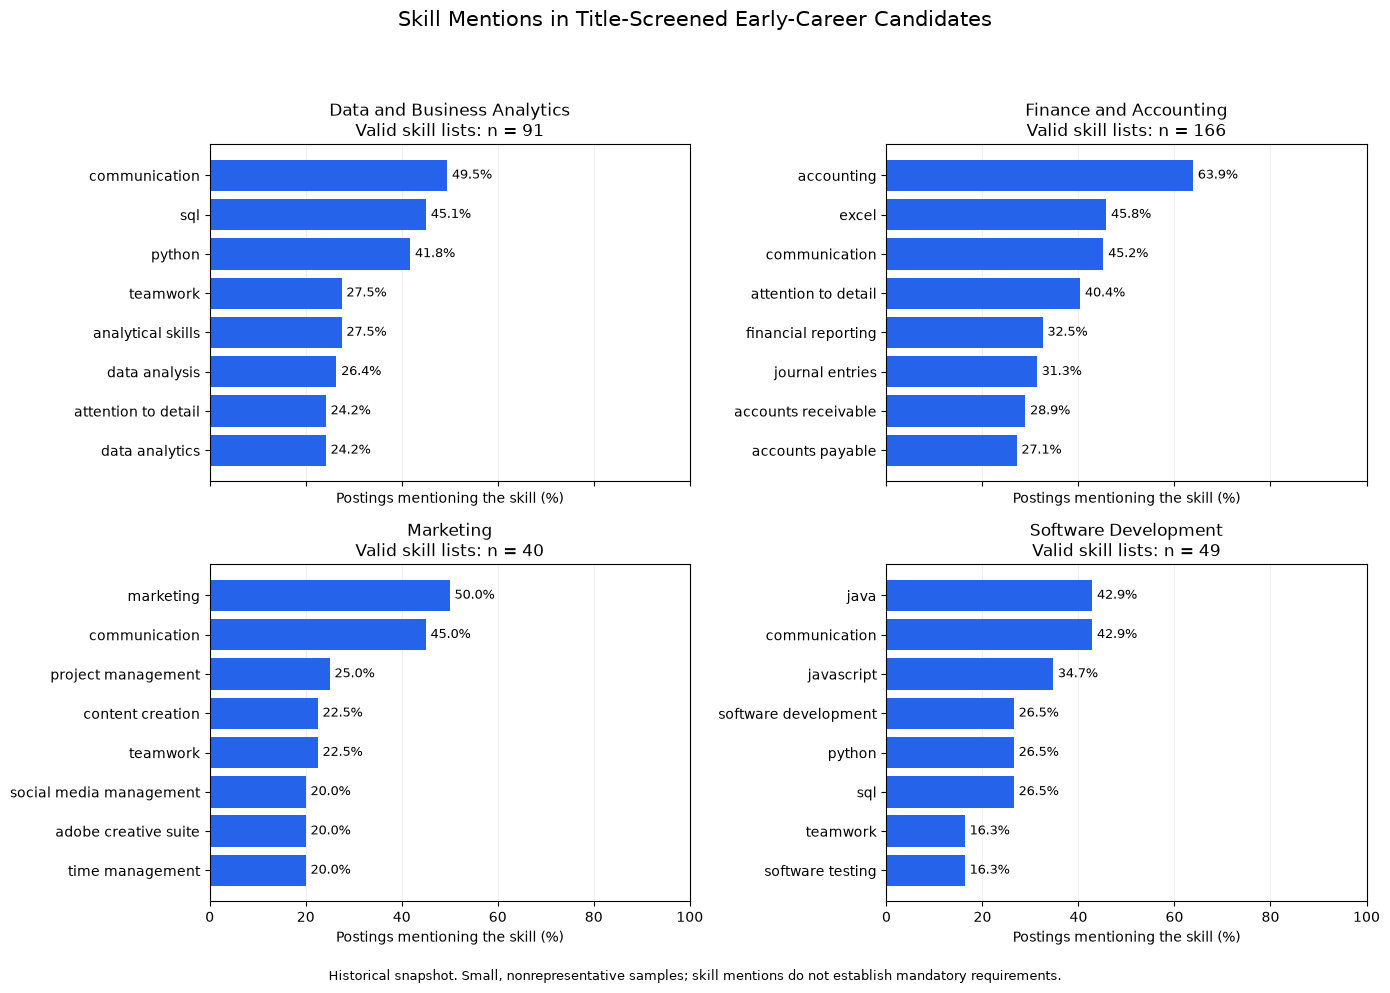

In [14]:
skill_aliases = {
    "communication skills": "communication",
    "microsoft excel": "excel",
    "ms excel": "excel",
}


def standardize_skill_terms(terms):
    return sorted({
        skill_aliases.get(term, term)
        for term in terms
    })


career_data["standardized_skills"] = (
    career_data["skill_terms"].apply(standardize_skill_terms)
)

early_career_data = career_data.loc[
    career_data["career_stage_screen"].eq("Early-Career Signal")
].copy()

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    sharex=True,
)

normalized_skill_tables = []

for ax, (pathway, group) in zip(
    axes.flat,
    early_career_data.groupby("career_pathway"),
):
    valid = group.loc[group["standardized_skills"].str.len().gt(0)]
    denominator = len(valid)

    counts = Counter(
        skill
        for skills in valid["standardized_skills"]
        for skill in skills
    )

    table = pd.DataFrame(
        counts.most_common(8),
        columns=["Skill", "Posting Count"],
    )

    table["Mention Percentage"] = (
        table["Posting Count"] / denominator * 100
    )

    table["Career Pathway"] = pathway
    normalized_skill_tables.append(table)

    plot_data = table.sort_values("Mention Percentage")

    ax.barh(
        plot_data["Skill"],
        plot_data["Mention Percentage"],
        color="#2563EB",
    )

    ax.set_title(f"{pathway}\nValid skill lists: n = {denominator}")
    ax.set_xlabel("Postings mentioning the skill (%)")
    ax.set_xlim(0, 100)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    for index, percentage in enumerate(plot_data["Mention Percentage"]):
        ax.text(
            percentage + 1,
            index,
            f"{percentage:.1f}%",
            va="center",
            fontsize=9,
        )

fig.suptitle(
    "Skill Mentions in Title-Screened Early-Career Candidates",
    fontsize=15,
)

fig.tight_layout(rect=[0, 0.03, 1, 0.94])

fig.text(
    0.5, 0.01,
    "Historical snapshot. Small, nonrepresentative samples; "
    "skill mentions do not establish mandatory requirements.",
    ha="center",
    fontsize=9,
)

plt.show()

normalized_skill_summary = pd.concat(
    normalized_skill_tables,
    ignore_index=True,
)

In [15]:
duplicate_audit = early_career_data.copy()

# Normalize comparison fields without changing the original values.
comparison_columns = []

for column in ["company", "job_title", "job_location"]:
    normalized_column = f"{column}_normalized"

    duplicate_audit[normalized_column] = (
        duplicate_audit[column]
        .fillna("")
        .str.strip()
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
    )

    comparison_columns.append(normalized_column)

# Do not group records with missing comparison information.
complete_keys = duplicate_audit[comparison_columns].ne("").all(axis=1)

duplicate_audit["possible_duplicate"] = False

duplicate_audit.loc[complete_keys, "possible_duplicate"] = (
    duplicate_audit.loc[complete_keys]
    .duplicated(subset=comparison_columns, keep=False)
)

suspected_duplicates = duplicate_audit.loc[
    duplicate_audit["possible_duplicate"]
].copy()

print(
    "Advertisements in possible duplicate groups:",
    len(suspected_duplicates),
)

duplicate_groups = (
    suspected_duplicates
    .groupby(comparison_columns)
    .size()
    .rename("Advertisement Count")
    .reset_index()
    .sort_values("Advertisement Count", ascending=False)
)

print("Possible duplicate groups:", len(duplicate_groups))

print("\nLargest possible duplicate groups:")
print(duplicate_groups.head(10).to_string(index=False))

Advertisements in possible duplicate groups: 56
Possible duplicate groups: 25

Largest possible duplicate groups:
        company_normalized                                                             job_title_normalized      job_location_normalized  Advertisement Count
             addison group                                                           entry level accountant      virginia, united states                    5
               rexus group                                                         junior software engineer washington dc-baltimore area                    4
                       mci                                                           entry-level accountant                  orlando, fl                    3
   localtel communications                                                           entry level accountant           east wenatchee, wa                    2
seasons kosher supermarket                                                                junior

In [16]:
duplicate_skill_audit = suspected_duplicates.copy()

# Skills were already standardized and sorted.
duplicate_skill_audit["skill_signature"] = (
    duplicate_skill_audit["standardized_skills"]
    .apply(tuple)
)

duplicate_skill_audit["blank_skill_list"] = (
    duplicate_skill_audit["standardized_skills"]
    .str.len()
    .eq(0)
)

group_audit = (
    duplicate_skill_audit
    .groupby(comparison_columns)
    .agg(
        advertisement_count=("job_link", "size"),
        distinct_skill_lists=("skill_signature", "nunique"),
        blank_skill_lists=("blank_skill_list", "sum"),
    )
    .reset_index()
)

same_nonblank_skills = (
    group_audit["distinct_skill_lists"].eq(1)
    & group_audit["blank_skill_lists"].eq(0)
)

print(f"Possible duplicate groups: {len(group_audit)}")
print(
    "Groups with identical nonblank skill lists:",
    int(same_nonblank_skills.sum()),
)
print(
    "Groups requiring further review:",
    int((~same_nonblank_skills).sum()),
)

# Show compact group-level results without long titles.
display(
    group_audit[
        [
            "advertisement_count",
            "distinct_skill_lists",
            "blank_skill_lists",
        ]
    ]
)

Possible duplicate groups: 25
Groups with identical nonblank skill lists: 0
Groups requiring further review: 25


,advertisement_count,distinct_skill_lists,blank_skill_lists
0,5,5,0
1,2,2,0
2,2,2,0
3,2,1,2
4,2,2,0
5,2,2,0
6,2,2,0
7,2,2,0
8,2,2,0
9,2,2,0


In [17]:
sensitivity_data = duplicate_audit.copy()

# Keep missing-key records separate rather than grouping them together.
sensitivity_data["comparison_group"] = sensitivity_data.apply(
    lambda row: (
        tuple(row[column] for column in comparison_columns)
        if all(row[column] for column in comparison_columns)
        else ("unique_record", row["job_link"])
    ),
    axis=1,
)


def skill_rates(skill_lists):
    valid_lists = [
        set(skills) for skills in skill_lists
        if len(skills) > 0
    ]

    counts = Counter(
        skill
        for skills in valid_lists
        for skill in skills
    )

    return pd.Series(
        {
            skill: count / len(valid_lists) * 100
            for skill, count in counts.items()
        },
        dtype=float,
    )


comparison_tables = []

for pathway, group in sensitivity_data.groupby("career_pathway"):
    # Original approach: each advertisement counts once.
    advertisement_rates = skill_rates(group["standardized_skills"])

    # Alternative approach: each organization-title-location group
    # counts once, using the union of skills mentioned in that group.
    grouped_skills = (
        group.groupby("comparison_group")["standardized_skills"]
        .apply(lambda lists: set().union(*lists))
    )

    group_rates = skill_rates(grouped_skills)

    comparison = pd.concat(
        [
            advertisement_rates.rename("Advertisement Rate (%)"),
            group_rates.rename("Grouped Rate (%)"),
        ],
        axis=1,
    ).fillna(0)

    comparison["Change (percentage points)"] = (
        comparison["Grouped Rate (%)"]
        - comparison["Advertisement Rate (%)"]
    )

    comparison["Absolute Change"] = (
        comparison["Change (percentage points)"].abs()
    )

    comparison["Career Pathway"] = pathway
    comparison.index.name = "Skill"
    comparison_tables.append(comparison.reset_index())

sensitivity_summary = pd.concat(
    comparison_tables,
    ignore_index=True,
)

largest_changes = (
    sensitivity_summary
    .sort_values("Absolute Change", ascending=False)
    .head(10)
)

display(
    largest_changes[
        [
            "Career Pathway",
            "Skill",
            "Advertisement Rate (%)",
            "Grouped Rate (%)",
            "Change (percentage points)",
        ]
    ].round(2)
)

,Career Pathway,Skill,Advertisement Rate (%),Grouped Rate (%),Change (percentage points)
3013,Software Development,javascript,34.69,40.48,5.78
2972,Software Development,java,42.86,47.62,4.76
2923,Software Development,communication,42.86,47.62,4.76
3011,Software Development,sql,26.53,30.95,4.42
3105,Software Development,software development,26.53,30.95,4.42
3040,Software Development,python,26.53,30.95,4.42
3280,Software Development,risk management,6.12,2.38,-3.74
2933,Software Development,us citizenship,8.16,4.76,-3.40
3209,Software Development,quality assurance,8.16,4.76,-3.40
1147,Finance and Accounting,attention to detail,40.36,43.71,3.35


## Sensitivity to Repeated Advertisements

There are 56 advertisements in 25 groups sharing the same
normalized organization, title, and location. No group has
identical nonblank standardized skill lists across all records.

Advertisements are retained because these groups cannot be
confirmed as duplicate vacancies.

An alternative group-based calculation changed some skill mention
rates by up to 5.78 percentage points. This indicates sensitivity
to repeated advertising and the counting method, particularly
in the small Software Development sample.

The dashboard will describe its metrics as advertisement-level
skill mentions rather than vacancy-level hiring demand.

In [18]:
# Count each term at most once per advertisement.
all_term_counts = Counter(
    term
    for terms in early_career_data["standardized_skills"]
    for term in set(terms)
)

# Flag possible qualifications or eligibility conditions for review.
# This does not automatically remove them.
qualification_pattern = (
    r"\bcitizenship\b|"
    r"\bwork authori[sz]ation\b|"
    r"\bauthori[sz]ed to work\b|"
    r"\bsecurity clearance\b|"
    r"\bdegree\b|"
    r"\bbachelor\b|"
    r"\bmaster['’]?s\b|"
    r"\bph\.?d\.?\b|"
    r"\bgpa\b|"
    r"\bdriver['’]?s licen[cs]e\b|"
    r"\byears? (?:of )?experience\b"
)

flagged_terms = pd.DataFrame(
    [
        {"Term": term, "Posting Count": count}
        for term, count in all_term_counts.items()
        if re.search(qualification_pattern, term, flags=re.I)
    ],
    columns=["Term", "Posting Count"],
).sort_values("Posting Count", ascending=False)

print(f"Distinct terms flagged for review: {len(flagged_terms)}")
print(flagged_terms.head(20).to_string(index=False))

Distinct terms flagged for review: 100
                                                Term  Posting Count
                                   bachelor's degree             31
                     bachelor's degree in accounting             16
          bachelor's degree in accounting or finance             12
                            bachelor's in accounting              6
                                      us citizenship              4
                              valid driver's license              4
                                     master's degree              4
                                   accounting degree              4
           bachelors degree in accounting or finance              4
                               us work authorization              3
aa or bs/ba degree in accounting finance or business              3
                           masters of science degree              3
                       bachelor's or master's degree              3
         

In [19]:
def separate_workshop_terms(terms):
    retained = []
    flagged = []

    for term in terms:
        if re.search(qualification_pattern, term, flags=re.I):
            flagged.append(term)
        else:
            retained.append(term)

    return retained, flagged


separated = career_data["standardized_skills"].apply(
    separate_workshop_terms
)

career_data["workshop_skills"] = separated.apply(
    lambda result: result[0]
)

career_data["qualification_like_terms"] = separated.apply(
    lambda result: result[1]
)

early_career_data = career_data.loc[
    career_data["career_stage_screen"].eq("Early-Career Signal")
].copy()

summary = (
    early_career_data
    .assign(
        has_workshop_terms=lambda df: (
            df["workshop_skills"].str.len().gt(0)
        ),
        has_flagged_terms=lambda df: (
            df["qualification_like_terms"].str.len().gt(0)
        ),
    )
    .groupby("career_pathway")
    .agg(
        candidate_postings=("job_link", "size"),
        nonblank_extracted_lists=("has_valid_skills", "sum"),
        postings_with_workshop_terms=("has_workshop_terms", "sum"),
        postings_with_flagged_terms=("has_flagged_terms", "sum"),
    )
)

print(summary.to_string())

                             candidate_postings  nonblank_extracted_lists  postings_with_workshop_terms  postings_with_flagged_terms
career_pathway                                                                                                                      
Data and Business Analytics                  94                        91                            91                           33
Finance and Accounting                      167                       166                           166                           80
Marketing                                    41                        40                            40                           14
Software Development                         52                        49                            49                           17


## Separating Skills from Qualifications

Extracted lists contain educational credentials and eligibility
conditions as well as skills.

Qualification-like terms are provisionally excluded from workshop
skill rankings using documented text rules. Original lists and
flagged terms are retained for inspection.

The exclusion rules may misclassify mixed or ambiguous terms.
Unflagged terms are not automatically considered verified skills.

Skill mention rates retain the denominator of advertisements with
nonblank extracted lists, rather than excluding advertisements
solely because their terms were removed from workshop rankings.

In [20]:
import json
from pathlib import Path

# Locate the project directory.
current_directory = Path.cwd()

project_root = (
    current_directory.parent
    if current_directory.name == "notebooks"
    else current_directory
)

if not (project_root / "notebooks").is_dir():
    raise ValueError(
        "Project folder not identified. Check Path.cwd() before exporting."
    )

data_directory = project_root / "data"
data_directory.mkdir(exist_ok=True)

export_data = early_career_data.copy()

# Preserve the possible-duplicate flag without removing advertisements.
duplicate_flags = duplicate_audit.set_index("job_link")[
    "possible_duplicate"
]

export_data["possible_duplicate"] = (
    export_data["job_link"]
    .map(duplicate_flags)
    .fillna(False)
    .astype(bool)
)

export_columns = [
    "job_link",
    "job_title",
    "company",
    "job_location",
    "career_pathway",
    "career_stage_screen",
    "job_level",
    "job_type",
    "first_seen",
    "location_status",
    "volunteer_title_signal",
    "possible_duplicate",
    "has_skill_record",
    "has_valid_skills",
    "job_skills",
    "workshop_skills",
    "qualification_like_terms",
]

export_data = export_data[export_columns].copy()

# Store lists as JSON so the app can read them reliably.
for column in ["workshop_skills", "qualification_like_terms"]:
    export_data[column] = export_data[column].apply(
        lambda values: json.dumps(values, ensure_ascii=False)
    )

output_path = data_directory / "career_postings.csv"
export_data.to_csv(output_path, index=False)

# Verify the saved file.
saved_data = pd.read_csv(output_path)

assert len(saved_data) == len(export_data)
assert saved_data["job_link"].is_unique

for column in ["workshop_skills", "qualification_like_terms"]:
    assert saved_data[column].map(
        lambda value: isinstance(json.loads(value), list)
    ).all()

file_size_mb = output_path.stat().st_size / 1_000_000
assert file_size_mb < 25, "The CSV exceeds the assignment's size guideline."

print(f"Saved file: {output_path}")
print(f"Rows: {len(saved_data):,}")
print(f"Columns: {len(saved_data.columns)}")
print(f"File size: {file_size_mb:.3f} MB")

Saved file: /Users/yuhandang/Documents/graduate-career-skills-radar/data/career_postings.csv
Rows: 354
Columns: 17
File size: 0.407 MB


In [21]:
unclear_candidates = career_data.loc[
    career_data["career_stage_screen"].eq("Unclear")
].copy()

unclear_candidates["normalized_title"] = (
    unclear_candidates["job_title"]
    .fillna("")
    .str.strip()
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
)

print(f"Candidates with unclear career stage: {len(unclear_candidates):,}")

for pathway, group in unclear_candidates.groupby("career_pathway"):
    title_counts = (
        group["normalized_title"]
        .value_counts()
        .head(10)
        .rename_axis("Job Title")
        .reset_index(name="Advertisement Count")
    )

    print(f"\n{pathway}")
    print(title_counts.to_string(index=False))

Candidates with unclear career stage: 14,663

Data and Business Analytics
                          Job Title  Advertisement Count
                   business analyst                  771
jde business analyst (supply chain)                  157
        jd edwards business analyst                  144
                      data engineer                  112
                     data scientist                  107
                       data analyst                   99
      business intelligence analyst                   68
    business intelligence developer                   54
                it business analyst                   53
                business analyst ii                   49

Finance and Accounting
                                                    Job Title  Advertisement Count
                                                   accountant                 1120
                                             staff accountant                  660
                          

In [22]:
# Additional titles relevant to career-pathway workshop planning.
# These titles do NOT establish graduate eligibility.
broader_title_lists = {
    "Data and Business Analytics": [
        "business analyst",
        "business analyst i",
        "data analyst",
        "data analyst i",
        "business intelligence analyst",
        "it business analyst",
        "data engineer",
        "data engineer i",
        "data scientist",
        "data scientist i",
    ],
    "Finance and Accounting": [
        "accountant",
        "accountant i",
        "staff accountant",
        "financial analyst",
        "financial analyst i",
        "finance analyst",
        "accounting analyst",
        "tax accountant",
        "project accountant",
        "cost accountant",
        "property accountant",
    ],
    "Marketing": [
        "marketing coordinator",
        "marketing specialist",
        "marketing analyst",
        "digital marketing specialist",
        "digital marketing coordinator",
        "social media specialist",
        "market research analyst",
    ],
    "Software Development": [
        "software engineer",
        "software engineer i",
        "software developer",
        "software developer i",
        "java developer",
        "python developer",
        "web developer",
        "application developer",
        "mobile application developer",
        "front end developer",
        "front-end developer",
        "back end developer",
        "back-end developer",
        "full stack developer",
        "full-stack developer",
        "embedded software engineer",
    ],
}


def normalize_title(value):
    if pd.isna(value):
        return ""

    return re.sub(r"\s+", " ", str(value).strip()).casefold()


broader_title_sets = {
    pathway: {normalize_title(title) for title in titles}
    for pathway, titles in broader_title_lists.items()
}

expanded_data = career_data.copy()

expanded_data["normalized_title"] = (
    expanded_data["job_title"].apply(normalize_title)
)

explicit_early = (
    expanded_data["career_stage_screen"]
    .eq("Early-Career Signal")
)

broader_match = expanded_data.apply(
    lambda row: (
        row["career_stage_screen"] == "Unclear"
        and row["normalized_title"] in broader_title_sets.get(
            row["career_pathway"], set()
        )
    ),
    axis=1,
)

expanded_data["analysis_scope"] = "Outside Selected Scope"

expanded_data.loc[
    explicit_early,
    "analysis_scope",
] = "Explicit Early-Career Title Signal"

expanded_data.loc[
    broader_match,
    "analysis_scope",
] = "Broader Title Match - Eligibility Unverified"

expanded_data = expanded_data.loc[
    explicit_early | broader_match
].copy()

print(f"Expanded candidate advertisements: {len(expanded_data):,}")

print("\nCounts by pathway and analysis scope:")
print(
    pd.crosstab(
        expanded_data["career_pathway"],
        expanded_data["analysis_scope"],
    ).to_string()
)

print("\nSkill-information coverage:")
print(
    expanded_data.groupby("career_pathway")
    .agg(
        advertisements=("job_link", "size"),
        nonblank_skill_lists=("has_valid_skills", "sum"),
    )
    .to_string()
)

Expanded candidate advertisements: 4,766

Counts by pathway and analysis scope:
analysis_scope               Broader Title Match - Eligibility Unverified  Explicit Early-Career Title Signal
career_pathway                                                                                               
Data and Business Analytics                                          1261                                  94
Finance and Accounting                                               2336                                 167
Marketing                                                             209                                  41
Software Development                                                  606                                  52

Skill-information coverage:
                             advertisements  nonblank_skill_lists
career_pathway                                                   
Data and Business Analytics            1355                  1323
Finance and Accounting           

In [23]:
def workshop_mention_rates(group):
    # Keep the denominator based on original nonblank skill lists.
    valid = group.loc[group["has_valid_skills"]]
    denominator = len(valid)

    if denominator == 0:
        return pd.Series(dtype=float)

    counts = Counter(
        skill
        for skills in valid["workshop_skills"]
        for skill in set(skills)
    )

    return pd.Series(
        {
            skill: count / denominator * 100
            for skill, count in counts.items()
        },
        dtype=float,
    )


scope_comparisons = []

for pathway, group in expanded_data.groupby("career_pathway"):
    explicit = group.loc[
        group["career_stage_screen"].eq("Early-Career Signal")
    ]

    broader = group.loc[
        ~group["career_stage_screen"].eq("Early-Career Signal")
    ]

    combined_rates = workshop_mention_rates(group)

    comparison = pd.concat(
        [
            combined_rates.rename("Combined (%)"),
            workshop_mention_rates(explicit).rename("Explicit (%)"),
            workshop_mention_rates(broader).rename("Broader (%)"),
        ],
        axis=1,
    ).fillna(0)

    # Show the five most mentioned terms in the combined sample.
    comparison = (
        comparison
        .sort_values("Combined (%)", ascending=False)
        .head(5)
    )

    comparison["Difference (pp)"] = (
        comparison["Broader (%)"] - comparison["Explicit (%)"]
    )

    comparison.index.name = "Skill"
    comparison["Career Pathway"] = pathway
    scope_comparisons.append(comparison.reset_index())

    print(f"\n{pathway}")
    print(
        comparison[
            ["Combined (%)", "Explicit (%)", "Broader (%)", "Difference (pp)"]
        ].round(1).to_string()
    )

scope_comparison_summary = pd.concat(
    scope_comparisons,
    ignore_index=True,
)


Data and Business Analytics
                    Combined (%)  Explicit (%)  Broader (%)  Difference (pp)
Skill                                                                       
communication               43.1          49.5         42.6             -6.8
data analysis               36.4          26.4         37.2             10.8
sql                         34.0          45.1         33.2            -11.9
business analysis           31.8           8.8         33.5             24.7
project management          26.2          11.0         27.4             16.4

Finance and Accounting
                     Combined (%)  Explicit (%)  Broader (%)  Difference (pp)
Skill                                                                        
accounting                   63.2          63.9         63.2             -0.7
excel                        46.1          45.8         46.1              0.3
communication                39.7          45.2         39.3             -5.9
financial reportin

In [24]:
expanded_export = expanded_data.copy()

# Recalculate possible duplicates for the expanded sample.
duplicate_keys = []

for column in ["company", "job_title", "job_location"]:
    key = f"{column}_normalized"

    expanded_export[key] = (
        expanded_export[column]
        .fillna("")
        .str.strip()
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
    )

    duplicate_keys.append(key)

complete_keys = expanded_export[duplicate_keys].ne("").all(axis=1)

expanded_export["possible_duplicate"] = False

expanded_export.loc[complete_keys, "possible_duplicate"] = (
    expanded_export.loc[complete_keys]
    .duplicated(subset=duplicate_keys, keep=False)
)

# Retain the previous export fields and add the analysis scope.
expanded_export_columns = export_columns + ["analysis_scope"]

expanded_export = expanded_export[
    expanded_export_columns
].copy()

for column in ["workshop_skills", "qualification_like_terms"]:
    expanded_export[column] = expanded_export[column].apply(
        lambda values: json.dumps(values, ensure_ascii=False)
    )

expanded_output_path = (
    data_directory / "career_postings_expanded.csv"
)

expanded_export.to_csv(expanded_output_path, index=False)

saved_expanded = pd.read_csv(expanded_output_path)

assert len(saved_expanded) == len(expanded_data)
assert saved_expanded["job_link"].is_unique

for column in ["workshop_skills", "qualification_like_terms"]:
    assert saved_expanded[column].map(
        lambda value: isinstance(json.loads(value), list)
    ).all()

expanded_size_mb = (
    expanded_output_path.stat().st_size / 1_000_000
)

assert expanded_size_mb < 25

print(f"Saved file: {expanded_output_path}")
print(f"Rows: {len(saved_expanded):,}")
print(f"Columns: {len(saved_expanded.columns)}")
print(f"File size: {expanded_size_mb:.3f} MB")
print(
    "Advertisements flagged as possible duplicates:",
    int(saved_expanded["possible_duplicate"].sum()),
)

Saved file: /Users/yuhandang/Documents/graduate-career-skills-radar/data/career_postings_expanded.csv
Rows: 4,766
Columns: 18
File size: 5.468 MB
Advertisements flagged as possible duplicates: 872


In [25]:
from collections import Counter

audit = expanded_data.copy()

# Normalize the fields used to identify possible duplicate groups.
group_columns = []

for column in ["company", "job_title", "job_location"]:
    normalized_column = f"{column}_normalized"
    audit[normalized_column] = (
        audit[column]
        .fillna("")
        .str.strip()
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
    )
    group_columns.append(normalized_column)

# Keep records with incomplete grouping fields separate.
audit["comparison_group"] = audit.apply(
    lambda row: (
        tuple(row[column] for column in group_columns)
        if all(row[column] for column in group_columns)
        else ("unique_record", row["job_link"])
    ),
    axis=1,
)


def calculate_rates(skill_lists, denominator):
    counts = Counter()

    for skills in skill_lists:
        counts.update(set(skills))

    if denominator == 0:
        return pd.Series(dtype="float64")

    return pd.Series(
        {
            skill: count / denominator * 100
            for skill, count in counts.items()
        },
        dtype="float64",
    )


scope_filters = {
    "All Selected Candidates": pd.Series(True, index=audit.index),
    "Explicit Early-Career Title Signals": audit["analysis_scope"].eq(
        "Explicit Early-Career Title Signal"
    ),
    "Broader Title Matches": audit["analysis_scope"].eq(
        "Broader Title Match - Eligibility Unverified"
    ),
}

comparison_tables = []

for scope_name, scope_filter in scope_filters.items():
    selected = audit.loc[scope_filter]

    for pathway, group in selected.groupby("career_pathway"):
        valid_ads = group.loc[group["has_valid_skills"]]

        advertisement_rates = calculate_rates(
            valid_ads["workshop_skills"],
            len(valid_ads),
        )

        # Alternative calculation: count each possible duplicate group once.
        # Use the union of retained skill terms within that group.
        grouped_skill_lists = []

        for _, possible_group in group.groupby(
            "comparison_group", sort=False
        ):
            valid_group = possible_group.loc[
                possible_group["has_valid_skills"]
            ]

            if valid_group.empty:
                continue

            combined_skills = set()

            for skills in valid_group["workshop_skills"]:
                combined_skills.update(skills)

            grouped_skill_lists.append(combined_skills)

        grouped_rates = calculate_rates(
            grouped_skill_lists,
            len(grouped_skill_lists),
        )

        comparison = pd.concat(
            [
                advertisement_rates.rename("Advertisement Rate (%)"),
                grouped_rates.rename("Grouped Rate (%)"),
            ],
            axis=1,
        ).fillna(0)

        comparison["Change (pp)"] = (
            comparison["Grouped Rate (%)"]
            - comparison["Advertisement Rate (%)"]
        )

        # Focus on the ten most frequently mentioned advertisement-level terms.
        top_terms = advertisement_rates.nlargest(10).index
        comparison = comparison.loc[top_terms].copy()

        comparison["Analysis Scope"] = scope_name
        comparison["Career Pathway"] = pathway
        comparison["Valid Advertisements"] = len(valid_ads)
        comparison["Valid Comparison Groups"] = len(grouped_skill_lists)

        comparison_tables.append(
            comparison.rename_axis("Skill").reset_index()
        )

duplicate_sensitivity = pd.concat(
    comparison_tables, ignore_index=True
)

duplicate_sensitivity["Absolute Change (pp)"] = (
    duplicate_sensitivity["Change (pp)"].abs()
)

print("Largest changes among the top ten skills in each scope and pathway:")

display(
    duplicate_sensitivity.sort_values(
        "Absolute Change (pp)", ascending=False
    )
    .head(12)[
        [
            "Analysis Scope",
            "Career Pathway",
            "Skill",
            "Valid Advertisements",
            "Valid Comparison Groups",
            "Advertisement Rate (%)",
            "Grouped Rate (%)",
            "Change (pp)",
        ]
    ]
    .round(2)
)

Largest changes among the top ten skills in each scope and pathway:


,Analysis Scope,Career Pathway,Skill,Valid Advertisements,Valid Comparison Groups,Advertisement Rate (%),Grouped Rate (%),Change (pp)
72,Explicit Early-Career Title Signals,Software Development,javascript,49,42,34.69,40.48,5.78
71,Explicit Early-Career Title Signals,Software Development,java,49,42,42.86,47.62,4.76
70,Explicit Early-Career Title Signals,Software Development,communication,49,42,42.86,47.62,4.76
75,Explicit Early-Career Title Signals,Software Development,software development,49,42,26.53,30.95,4.42
74,Explicit Early-Career Title Signals,Software Development,python,49,42,26.53,30.95,4.42
73,Explicit Early-Career Title Signals,Software Development,sql,49,42,26.53,30.95,4.42
53,Explicit Early-Career Title Signals,Finance and Accounting,attention to detail,166,151,40.36,43.71,3.35
52,Explicit Early-Career Title Signals,Finance and Accounting,communication,166,151,45.18,48.34,3.16
80,Broader Title Matches,Data and Business Analytics,communication,1232,1080,42.61,45.65,3.03
0,All Selected Candidates,Data and Business Analytics,communication,1323,1165,43.08,45.84,2.75


## EDA Conclusions and Dashboard Design Implications

The dashboard dataset contains 4,766 selected job advertisements across
four career pathways. The exported CSV is 5.468 MB, below the assignment's
approximate 25 MB limit. The dataset was reduced through rule-based
selection rather than random sampling.

Of these advertisements, 354 have explicit early-career signals in their
titles. The remaining 4,412 match selected broader role titles, but their
eligibility requirements have not been verified. These groups must remain
distinguishable in the dashboard.

Skill information is available for 4,697 advertisements. Skill mention
percentages use advertisements with nonblank original skill lists as the
denominator. Each retained skill is counted at most once per advertisement.
Extracted terms are indicators of skill mentions, not verified mandatory
requirements.

Skill patterns differ between the explicit early-career and broader-title
groups. For example, SQL appears in 45.1% of valid early-career skill lists
in Data and Business Analytics, compared with 33.2% in the broader-title
group. An analysis-scope selector is therefore necessary.

A total of 872 advertisements belong to possible duplicate groups based
on normalized company, title, and location. These records were retained
because matching these fields does not establish that the advertisements
represent the same vacancy.

A sensitivity analysis compared advertisement-level rates with an
alternative calculation that counted each comparison group once and
combined its retained skill terms. Among the advertisement-level top ten
skills in each pathway and analysis scope, the largest absolute change
was 5.78 percentage points. This alternative is not a validated
deduplication method.

The dashboard will support skill-workshop planning by a Director of
Career Services at a U.S. university. It will not measure graduate
employment outcomes, current vacancy availability, or student skill gaps.

The prototype uses a historical snapshot with first-seen dates from
January 12–17, 2024. These are collection dates rather than verified job
publication dates. The proposed production workflow would refresh data
weekly and support monthly workshop-planning reviews.

In [26]:
location_check = expanded_data.copy()

location_check["location_display"] = (
    location_check["job_location"]
    .fillna("")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

location_summary = (
    location_check.groupby("location_display")
    .agg(
        Advertisements=("job_link", "size"),
        Valid_Skill_Lists=("has_valid_skills", "sum"),
        Career_Pathways=("career_pathway", "nunique"),
    )
    .sort_values("Advertisements", ascending=False)
)

print(
    "Distinct location labels:",
    location_check["location_display"].nunique(),
)

print("\nTop 25 location labels:")

display(location_summary.head(25))

Distinct location labels: 1355

Top 25 location labels:


,Advertisements,Valid_Skill_Lists,Career_Pathways
location_display,,,
"New York, NY",109,107,4
"Atlanta, GA",93,88,4
"Chicago, IL",83,82,4
"Dallas, TX",79,76,4
"Houston, TX",75,72,4
"Washington, DC",62,58,4
"Austin, TX",59,59,4
"Miami, FL",56,56,4
"Jacksonville, FL",45,45,4


In [27]:
example_columns = [
    "job_title",
    "company",
    "job_location",
    "career_pathway",
    "analysis_scope",
    "workshop_skills",
    "job_link",
]

examples = expanded_data.loc[
    expanded_data["has_valid_skills"],
    example_columns,
].head(5)

with pd.option_context(
    "display.max_colwidth", 100,
    "display.max_columns", None,
):
    display(examples)

,job_title,company,job_location,career_pathway,analysis_scope,workshop_skills,job_link
8,Junior Accountant,"Tier 1 Consulting, Inc.","Napa, CA",Finance and Accounting,Explicit Early-Career Title Signal,"[accounts payable, accounts receivable, bilingual (english/spanish), communication, detailorient...",https://www.linkedin.com/jobs/view/junior-accountant-at-tier-1-consulting-inc-3805599433
15,Marketing Coordinator,Oldcastle APG,"Minnetonka, MN",Marketing,Broader Title Match - Eligibility Unverified,"[2+ years brand/marketing experience, agency coordination, brand communications, campaign manage...",https://www.linkedin.com/jobs/view/marketing-coordinator-at-oldcastle-apg-3796582271
22,Staff Accountant,Career Resource Services,"Dallas, TX",Finance and Accounting,Broader Title Match - Eligibility Unverified,"[ability to work with minimal supervision, accounting, accrual tracking, client and board report...",https://www.linkedin.com/jobs/view/staff-accountant-at-career-resource-services-3806872938
38,Tax Accountant,Atlas Search,"Greenwich, CT",Finance and Accounting,Broader Title Match - Eligibility Unverified,"[accounting experience, ad hoc requests, business requirements, cash flows, client relationship ...",https://www.linkedin.com/jobs/view/tax-accountant-at-atlas-search-3804373655
39,Accountant,Coldwell Banker Commercial Devonshire Realty,"Champaign, IL",Finance and Accounting,Broader Title Match - Eligibility Unverified,"[35 years of accounting experience, accounts receivable/payable summary, annual budgets and cash...",https://www.linkedin.com/jobs/view/accountant-at-coldwell-banker-commercial-devonshire-realty-37...


In [28]:
valid_state_codes = set(
    """
    AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA
    ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK
    OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC
    """.split()
)

expanded_data["location_display"] = (
    expanded_data["job_location"]
    .fillna("")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Extract an explicit trailing state code, such as "Chicago, IL".
# This does not infer a state from city or metropolitan-area names.
extracted_state = expanded_data["location_display"].str.extract(
    r",\s*([A-Z]{2})(?:\s+\d{5}(?:-\d{4})?)?\s*$",
    expand=False,
)

expanded_data["target_state"] = (
    extracted_state
    .where(extracted_state.isin(valid_state_codes))
    .fillna("Unspecified")
)

state_summary = (
    expanded_data.groupby("target_state")
    .agg(
        Advertisements=("job_link", "size"),
        Valid_Skill_Lists=("has_valid_skills", "sum"),
        Career_Pathways=("career_pathway", "nunique"),
    )
    .sort_values("Advertisements", ascending=False)
)

print("State-code screening results:")
display(state_summary.head(15))

unspecified = expanded_data[
    expanded_data["target_state"].eq("Unspecified")
]

print(
    "\nAdvertisements without an explicitly parsed state:",
    len(unspecified),
)

print("\nMost frequent location labels requiring review:")
display(
    unspecified["location_display"]
    .value_counts()
    .head(15)
    .rename("Advertisements")
)

State-code screening results:


,Advertisements,Valid_Skill_Lists,Career_Pathways
target_state,,,
CA,461,455,4
TX,408,395,4
FL,392,391,4
NY,270,264,4
VA,243,233,4
Unspecified,240,239,4
PA,201,198,4
IL,193,190,4
NJ,187,185,4



Advertisements without an explicitly parsed state: 240

Most frequent location labels requiring review:


location_display
New York City Metropolitan Area    28
New York, United States            24
Dallas-Fort Worth Metroplex        17
Los Angeles Metropolitan Area      13
Miami-Fort Lauderdale Area         10
Indiana, United States             10
Austin, Texas Metropolitan Area     9
Atlanta Metropolitan Area           9
Denver Metropolitan Area            8
Greater Chicago Area                7
Greater Boston                      7
Virginia, United States             7
Maryland, United States             6
Greater Orlando                     6
United States                       6
Name: Advertisements, dtype: int64[pyarrow]

In [29]:
# Map only reviewed labels that clearly identify a single state.
reviewed_state_mapping = {
    "indiana, united states": "IN",
    "virginia, united states": "VA",
    "maryland, united states": "MD",
    "dallas-fort worth metroplex": "TX",
    "los angeles metropolitan area": "CA",
    "miami-fort lauderdale area": "FL",
    "austin, texas metropolitan area": "TX",
    "denver metropolitan area": "CO",
    "greater orlando": "FL",
}

normalized_locations = (
    expanded_data["location_display"]
    .str.casefold()
    .str.replace("–", "-", regex=False)
    .str.replace("—", "-", regex=False)
)

mapped_states = normalized_locations.map(reviewed_state_mapping)

update_mask = (
    expanded_data["target_state"].eq("Unspecified")
    & mapped_states.notna()
)

expanded_data.loc[update_mask, "target_state"] = (
    mapped_states.loc[update_mask]
)

print("Advertisements with a parsed or reviewed state:",
      expanded_data["target_state"].ne("Unspecified").sum())

print("Advertisements with unspecified state:",
      expanded_data["target_state"].eq("Unspecified").sum())

Advertisements with a parsed or reviewed state: 4612
Advertisements with unspecified state: 154


In [30]:
# Extend the existing qualification screen to catch numeric
# experience phrases, including terms with words before "experience".
existing_pattern = getattr(
    qualification_pattern,
    "pattern",
    qualification_pattern,
)

qualification_pattern = re.compile(
    f"(?:{existing_pattern})"
    r"|\b\d+(?:\s*[-–]\s*\d+)?\s*\+?\s*years?\b",
    flags=re.IGNORECASE,
)


def separate_workshop_terms(terms):
    retained = []
    flagged = []

    for term in terms:
        if qualification_pattern.search(term):
            flagged.append(term)
        else:
            retained.append(term)

    return retained, flagged


reprocessed_terms = expanded_data["standardized_skills"].apply(
    separate_workshop_terms
)

expanded_data["workshop_skills"] = reprocessed_terms.apply(
    lambda result: result[0]
)

expanded_data["qualification_like_terms"] = reprocessed_terms.apply(
    lambda result: result[1]
)

print("Examples of withheld experience terms:")

experience_examples = sorted({
    term
    for terms in expanded_data["qualification_like_terms"]
    for term in terms
    if re.search(r"\b\d+.*\byears?\b", term)
})

for term in experience_examples[:15]:
    print("-", term)

Examples of withheld experience terms:
- * 3+ years of experience in accounting
- * at least 1 year of casino gaming/audit experience and/or equivalent
- +5 years' experience in project management
- 0 years experience
- 01 year experience in accounting
- 01 year experience with itsm systems
- 01 year work experience
- 02 years accounting experience
- 02 years experience
- 02 years of accounting experience
- 02 years of experience
- 02 years of experience in accounting
- 02 years of experience in accounting or finance
- 02 years of related work experience
- 02 years of work experience


In [31]:
import json

final_export = expanded_data.copy()

# Recalculate possible-duplicate flags for the full selected dataset.
duplicate_columns = []

for column in ["company", "job_title", "job_location"]:
    normalized_column = f"{column}_normalized"

    final_export[normalized_column] = (
        final_export[column]
        .fillna("")
        .str.strip()
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
    )

    duplicate_columns.append(normalized_column)

complete_keys = final_export[duplicate_columns].ne("").all(axis=1)

final_export["possible_duplicate"] = False

final_export.loc[complete_keys, "possible_duplicate"] = (
    final_export.loc[complete_keys]
    .duplicated(subset=duplicate_columns, keep=False)
)

final_columns = [
    "job_link",
    "job_title",
    "company",
    "job_location",
    "target_state",
    "career_pathway",
    "career_stage_screen",
    "analysis_scope",
    "job_level",
    "job_type",
    "first_seen",
    "location_status",
    "volunteer_title_signal",
    "possible_duplicate",
    "has_skill_record",
    "has_valid_skills",
    "job_skills",
    "workshop_skills",
    "qualification_like_terms",
]

final_export = final_export[final_columns].copy()

# Store list fields as JSON so the app can read them consistently.
for column in ["workshop_skills", "qualification_like_terms"]:
    final_export[column] = final_export[column].apply(
        lambda values: json.dumps(values, ensure_ascii=False)
    )

output_path = data_directory / "career_postings_expanded.csv"

# Check the data before replacing the previous export.
assert len(final_export) == 4_766
assert final_export["job_link"].is_unique
assert int(final_export["has_valid_skills"].sum()) == 4_697
assert final_export["target_state"].notna().all()

final_export.to_csv(output_path, index=False)

# Verify the saved file.
saved_data = pd.read_csv(output_path)

assert len(saved_data) == len(final_export)
assert saved_data["job_link"].is_unique

for column in ["workshop_skills", "qualification_like_terms"]:
    assert saved_data[column].apply(
        lambda value: isinstance(json.loads(value), list)
    ).all()

file_size_mb = output_path.stat().st_size / 1_000_000
assert file_size_mb < 25

print(f"Saved file: {output_path}")
print(f"Rows: {len(saved_data):,}")
print(f"Columns: {len(saved_data.columns)}")
print(f"File size: {file_size_mb:.3f} MB")
print(
    "Advertisements with unspecified state:",
    saved_data["target_state"].eq("Unspecified").sum(),
)

# Recalculate the leading skill terms after qualification screening.
print("\nUpdated top three skill mentions by pathway:")

for pathway, group in expanded_data.groupby("career_pathway"):
    rates = workshop_mention_rates(group).nlargest(3)

    print(f"\n{pathway}")
    display(
        rates.rename("Mention Percentage")
        .rename_axis("Skill")
        .reset_index()
        .round(1)
    )

Saved file: /Users/yuhandang/Documents/graduate-career-skills-radar/data/career_postings_expanded.csv
Rows: 4,766
Columns: 19
File size: 5.484 MB
Advertisements with unspecified state: 154

Updated top three skill mentions by pathway:

Data and Business Analytics


,Skill,Mention Percentage
0,communication,43.1
1,data analysis,36.4
2,sql,34.0



Finance and Accounting


,Skill,Mention Percentage
0,accounting,63.2
1,excel,46.1
2,communication,39.7



Marketing


,Skill,Mention Percentage
0,communication,47.1
1,project management,42.5
2,marketing,40.4



Software Development


,Skill,Mention Percentage
0,java,34.7
1,python,28.7
2,communication,28.5
